# Copia de consulta — no editar ni usar para entrenar

Original: `notebooks/03_revision_anotaciones.ipynb` · SHA-256 (UTF-8, saltos LF): `57c054954dbae8b0ab9da11b948f695ce1fb9e845dcf5086cf59a9b32373c369`.

Tipo: **ejecucion_completa**. Fecha de ejecución/consulta: 2026-11-10T03:26:47.818623+00:00. Commit de ejecución: `92f76cf1e05f11a43be6d79a29c6e515d17f2721`.

Entorno de ejecución: `{"Pillow": "12.1.1", "ejecutable_kernel": "python", "figure_dpi": 55, "kernel": "python3", "matplotlib": "3.10.8", "nbclient": "0.10.4", "numpy": "1.26.4", "pandas": "2.2.2", "python": "3.11.9", "savefig_dpi": 55, "scikit-learn": "1.7.2"}`. Publicación: 2026-11-10T00:35:59-03:00. Commit de referencia del código: `92f76cf1e05f11a43be6d79a29c6e515d17f2721`.

Preparación del insumo: sin celdas omitidas.

Celdas ejecutadas (índices del original): [2, 4, 6, 8, 10]. Familia del test: no aplica.

Una consulta de corridas guardadas muestra resultados reales ya existentes; no reproduce los logs del entrenamiento. Val eligió checkpoints y se usa para reportar. Se quitaron widgets y formatos activos; en test se quitaron todas las imágenes.


<a href="https://colab.research.google.com/github/candeperles/PDI-TP/blob/main/notebooks/03_revision_anotaciones.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 03. Revisión de anotaciones

Revisión reproducible de las 17 cajas de clases 1/2, las 37 cajas pequeñas positivas,
la caja degenerada y una muestra de 18 imágenes con etiqueta vacía.
No cambia datos ni split. Ejecutar todo.

Los [criterios de trabajo](../docs/criterios_datos.md) y el
[registro de revisión](../docs/revision_anotaciones.csv) están versionados.
Las observaciones son de una revisión visual de Codex; N06 y N16 requieren segunda revisión.


In [1]:
# --- Setup: correr siempre primero ---
import os
import subprocess
import sys
from pathlib import Path

if "google.colab" in sys.modules:
    repo = Path("/content/PDI-TP")
    if repo.is_dir():
        subprocess.run(["git", "-C", str(repo), "pull", "--ff-only", "-q"], check=True)
    else:
        subprocess.run(["git", "clone", "-q", "https://github.com/candeperles/PDI-TP.git", str(repo)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(repo / "requirements.txt")], check=True)
else:
    # Funciona al abrir Jupyter desde la raíz o desde notebooks/.
    repo = next((p for p in (Path.cwd(), Path.cwd().parent)
                 if (p / "pdi_tp" / "entorno.py").is_file()), None)
    if repo is None:
        raise FileNotFoundError("Abrí Jupyter desde la raíz del repositorio o desde notebooks/.")
os.chdir(repo)
sys.path.insert(0, str(repo))

from pdi_tp import entorno, datos, resultados, split
rutas = entorno.preparar(usar_drive=False)  # no entrena: no monta Drive ni crea carpetas


Dataset:    C:\Users\cande\PDI-TP\data\grupo_5 (900 imágenes)
Resultados: C:\Users\cande\PDI-TP\resultados_locales\resultados (se crea al guardar un modelo)
GPU:        no hay GPU NVIDIA (corriendo en local)


## Construir los mismos casos

Se incluyen todas las cajas minoritarias, pequeñas positivas e inválidas. Los negativos
se muestrean con semilla 42, tres por combinación fuente/split disponible. Es una
muestra exploratoria, no una estimación de error sobre todos los negativos.


In [2]:
from pdi_tp import validacion, revision
import pandas as pd
from IPython.display import Image as MostrarImagen

informe = validacion.validar(rutas)
casos = revision.seleccionar_casos(informe, semilla=42, negativos_por_estrato=3)
registro = pd.read_csv(rutas.repo / "docs" / "revision_anotaciones.csv", dtype={"linea": "Int64", "clase": "Int64"})
columnas = list(casos.columns)
pd.testing.assert_frame_equal(casos.reset_index(drop=True), registro[columnas].reset_index(drop=True),
                              check_dtype=False, check_exact=False, atol=1e-6, rtol=0)
revision_completa = casos.merge(registro[["caso", "observacion", "decision", "estado"]],
                               on="caso", validate="one_to_one")
display(casos.groupby(["categoria", "split"]).size().rename("casos").to_frame())
salida = rutas.analisis / "revision_anotaciones"
galerias = revision.exportar_galerias(casos, informe, rutas, salida, formato="jpg")
revision_completa.to_csv(salida / "revision_completa.csv", index=False, encoding="utf-8")
print(f"Galerías y registro (solo en esta sesión, no se guardan en Drive): {salida}")


casos
categoria           split       
caja_invalida       train      1
caja_pequena        train     24
                    val       13
clase_minoritaria   train     11
                    val        6
muestra_sin_paneles train      9
                    val        9

Galerías y registro (solo en esta sesión, no se guardan en Drive): C:\Users\cande\PDI-TP\resultados_locales\analisis\revision_anotaciones


## Clases 1 y 2: confianza de origen

El [artículo original, Technical Validation](https://www.nature.com/articles/s41597-023-02539-8)
define 0/1/2 como confianza alta/moderada/baja en `solarpanels_hd`.
El [cotejo con Figshare](../docs/cotejo_clases.csv) verificó las 17 cajas locales.
No son tipos distintos de panel. En otras fuentes no se infiere confianza a partir del ID 0.

Cada caso muestra la imagen completa y un zoom con contexto. El zoom no agrega resolución.
El criterio es una clase `panel` en un futuro derivado, conservando confianza y clase originales.


,caso,archivo,linea_local,clase,etiqueta_fuente,linea_fuente,columna_recorte,fila_recorte,coincide
0,R01,solarpanels_hd_1__x0_16473_y0_15637_dxdy_832_0...,1,2,solarpanels_hd_1__x0_16473_y0_15637_dxdy_832.txt,1,1,0,True
1,R02,solarpanels_hd_1__x0_16815_y0_17593_dxdy_832_1...,1,2,solarpanels_hd_1__x0_16815_y0_17593_dxdy_832.txt,7,0,1,True
2,R03,solarpanels_hd_1__x0_18698_y0_21896_dxdy_832_3...,1,2,solarpanels_hd_1__x0_18698_y0_21896_dxdy_832.txt,16,2,3,True
3,R04,solarpanels_hd_1__x0_18744_y0_22105_dxdy_832_2...,1,2,solarpanels_hd_1__x0_18744_y0_22105_dxdy_832.txt,14,2,2,True
4,R05,solarpanels_hd_1__x0_4548_y0_16371_dxdy_832_0_...,1,2,solarpanels_hd_1__x0_4548_y0_16371_dxdy_832.txt,1,1,0,True
5,R06,solarpanels_hd_1__x0_4791_y0_16369_dxdy_832_0_...,1,2,solarpanels_hd_1__x0_4791_y0_16369_dxdy_832.txt,1,0,0,True
6,R07,solarpanels_hd_2__x0_10085_y0_11459_dxdy_832_0...,1,2,solarpanels_hd_2__x0_10085_y0_11459_dxdy_832.txt,1,1,0,True
7,R08,solarpanels_hd_2__x0_10179_y0_13259_dxdy_832_3...,1,1,solarpanels_hd_2__x0_10179_y0_13259_dxdy_832.txt,6,3,3,True
8,R09,solarpanels_hd_2__x0_16693_y0_5989_dxdy_832_2_...,1,1,solarpanels_hd_2__x0_16693_y0_5989_dxdy_832.txt,3,2,2,True
9,R10,solarpanels_hd_2__x0_16693_y0_5989_dxdy_832_2_...,3,1,solarpanels_hd_2__x0_16693_y0_5989_dxdy_832.txt,5,2,2,True


,caso,categoria,archivo,linea,clase,split,fuente,w_px,h_px,observacion,decision,estado
0,R01,clase_minoritaria,solarpanels_hd_1__x0_16473_y0_15637_dxdy_832_0...,1,2,train,solarpanels_hd,48.000000,57.846272,Estructura rayada sobre cubierta; identidad vi...,fusionar_a_panel_conservar_confianza_en_derivado,revisado_visual_Codex
1,R02,clase_minoritaria,solarpanels_hd_1__x0_16815_y0_17593_dxdy_832_1...,1,2,train,solarpanels_hd,77.538560,83.692288,Estructura alargada sobre cubierta; posible co...,fusionar_a_panel_conservar_confianza_en_derivado,revisado_visual_Codex
2,R03,clase_minoritaria,solarpanels_hd_1__x0_18698_y0_21896_dxdy_832_3...,1,2,train,solarpanels_hd,57.846272,119.384576,Estructura acristalada alargada; misma escena ...,fusionar_a_panel_conservar_confianza_en_derivado,revisado_visual_Codex
3,R04,clase_minoritaria,solarpanels_hd_1__x0_18744_y0_22105_dxdy_832_2...,1,2,train,solarpanels_hd,57.846272,119.384576,Estructura acristalada alargada; misma escena ...,fusionar_a_panel_conservar_confianza_en_derivado,revisado_visual_Codex
4,R05,clase_minoritaria,solarpanels_hd_1__x0_4548_y0_16371_dxdy_832_0_...,1,2,val,solarpanels_hd,50.461440,39.384576,Objeto oscuro alargado sobre tejado; misma esc...,fusionar_a_panel_conservar_confianza_en_derivado,revisado_visual_Codex
5,R06,clase_minoritaria,solarpanels_hd_1__x0_4791_y0_16369_dxdy_832_0_...,1,2,val,solarpanels_hd,50.461440,39.384576,Objeto oscuro alargado sobre tejado; misma esc...,fusionar_a_panel_conservar_confianza_en_derivado,revisado_visual_Codex
6,R07,clase_minoritaria,solarpanels_hd_2__x0_10085_y0_11459_dxdy_832_0...,1,2,train,solarpanels_hd,39.384576,40.615424,Módulo claro con bandas sobre cubierta; identi...,fusionar_a_panel_conservar_confianza_en_derivado,revisado_visual_Codex
7,R08,clase_minoritaria,solarpanels_hd_2__x0_10179_y0_13259_dxdy_832_3...,1,1,train,solarpanels_hd,41.846272,45.538560,Rectángulos oscuros alineados sobre tejado; co...,fusionar_a_panel_conservar_confianza_en_derivado,revisado_visual_Codex
8,R09,clase_minoritaria,solarpanels_hd_2__x0_16693_y0_5989_dxdy_832_2_...,1,1,train,solarpanels_hd,123.076864,99.692288,Conjunto con bandas sobre cubierta; certeza li...,fusionar_a_panel_conservar_confianza_en_derivado,revisado_visual_Codex
9,R10,clase_minoritaria,solarpanels_hd_2__x0_16693_y0_5989_dxdy_832_2_...,3,1,train,solarpanels_hd,119.384576,92.307712,Conjunto con bandas sobre cubierta; certeza li...,fusionar_a_panel_conservar_confianza_en_derivado,revisado_visual_Codex


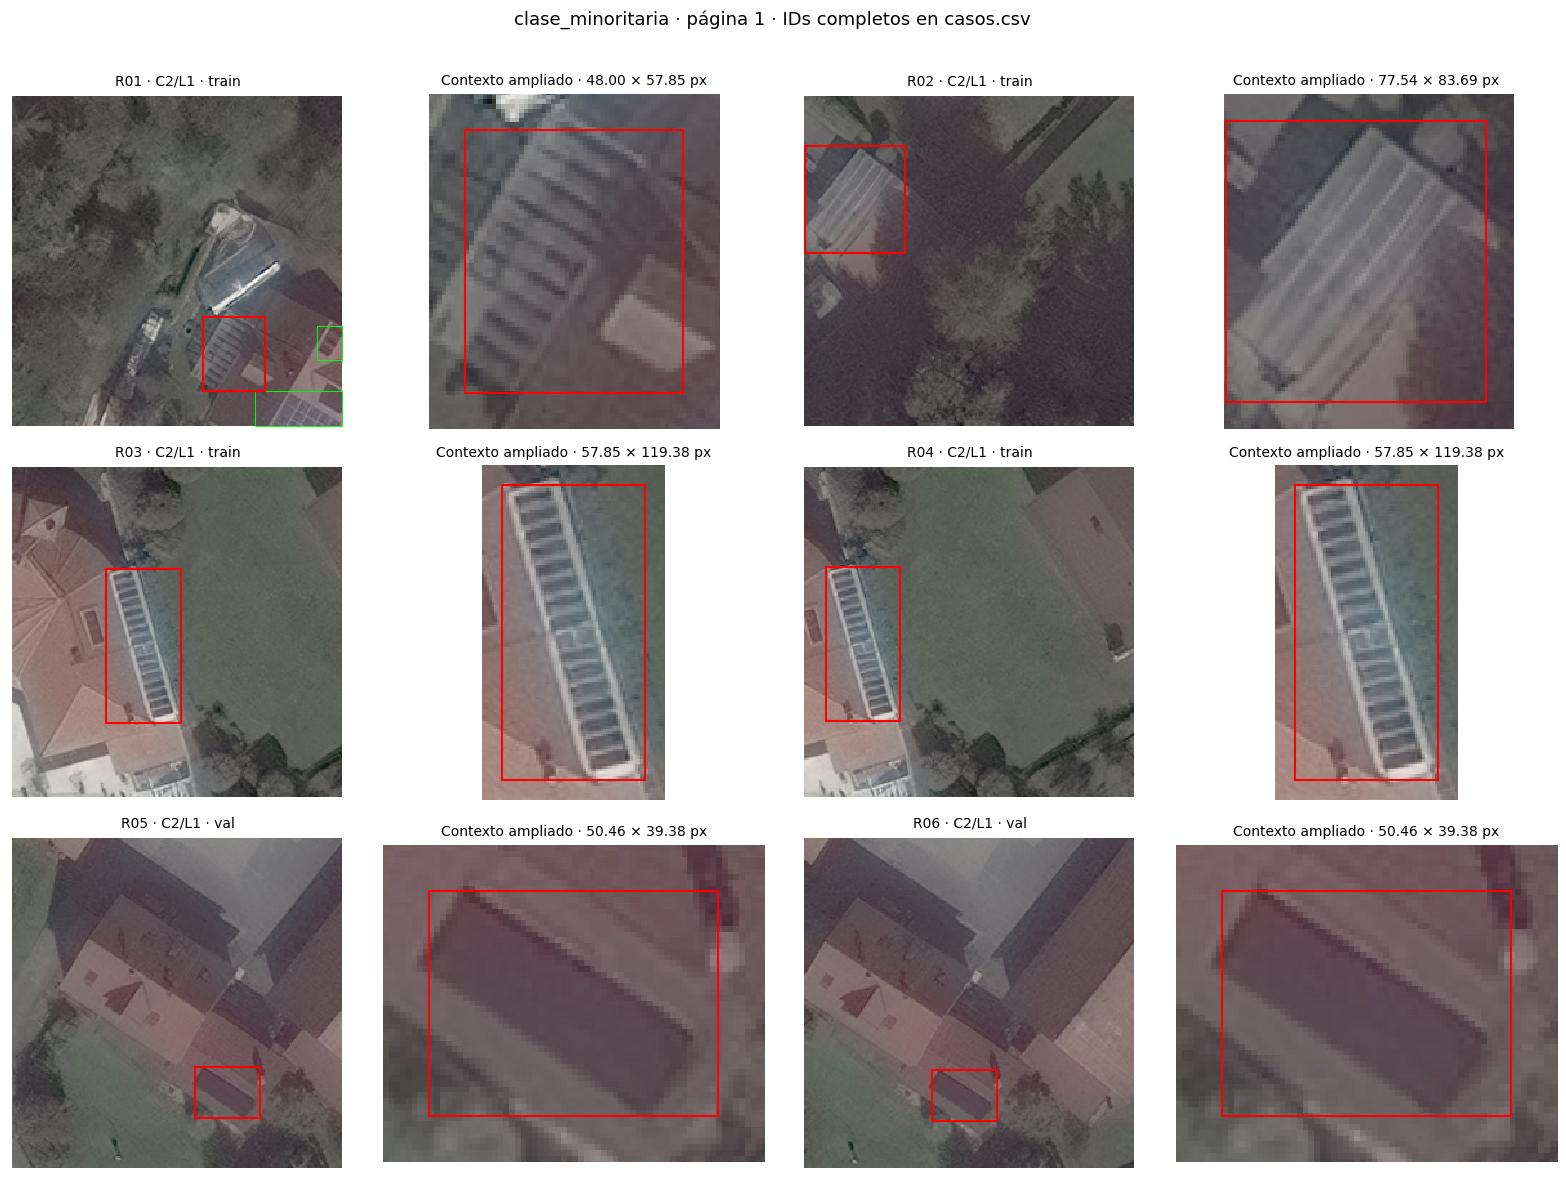

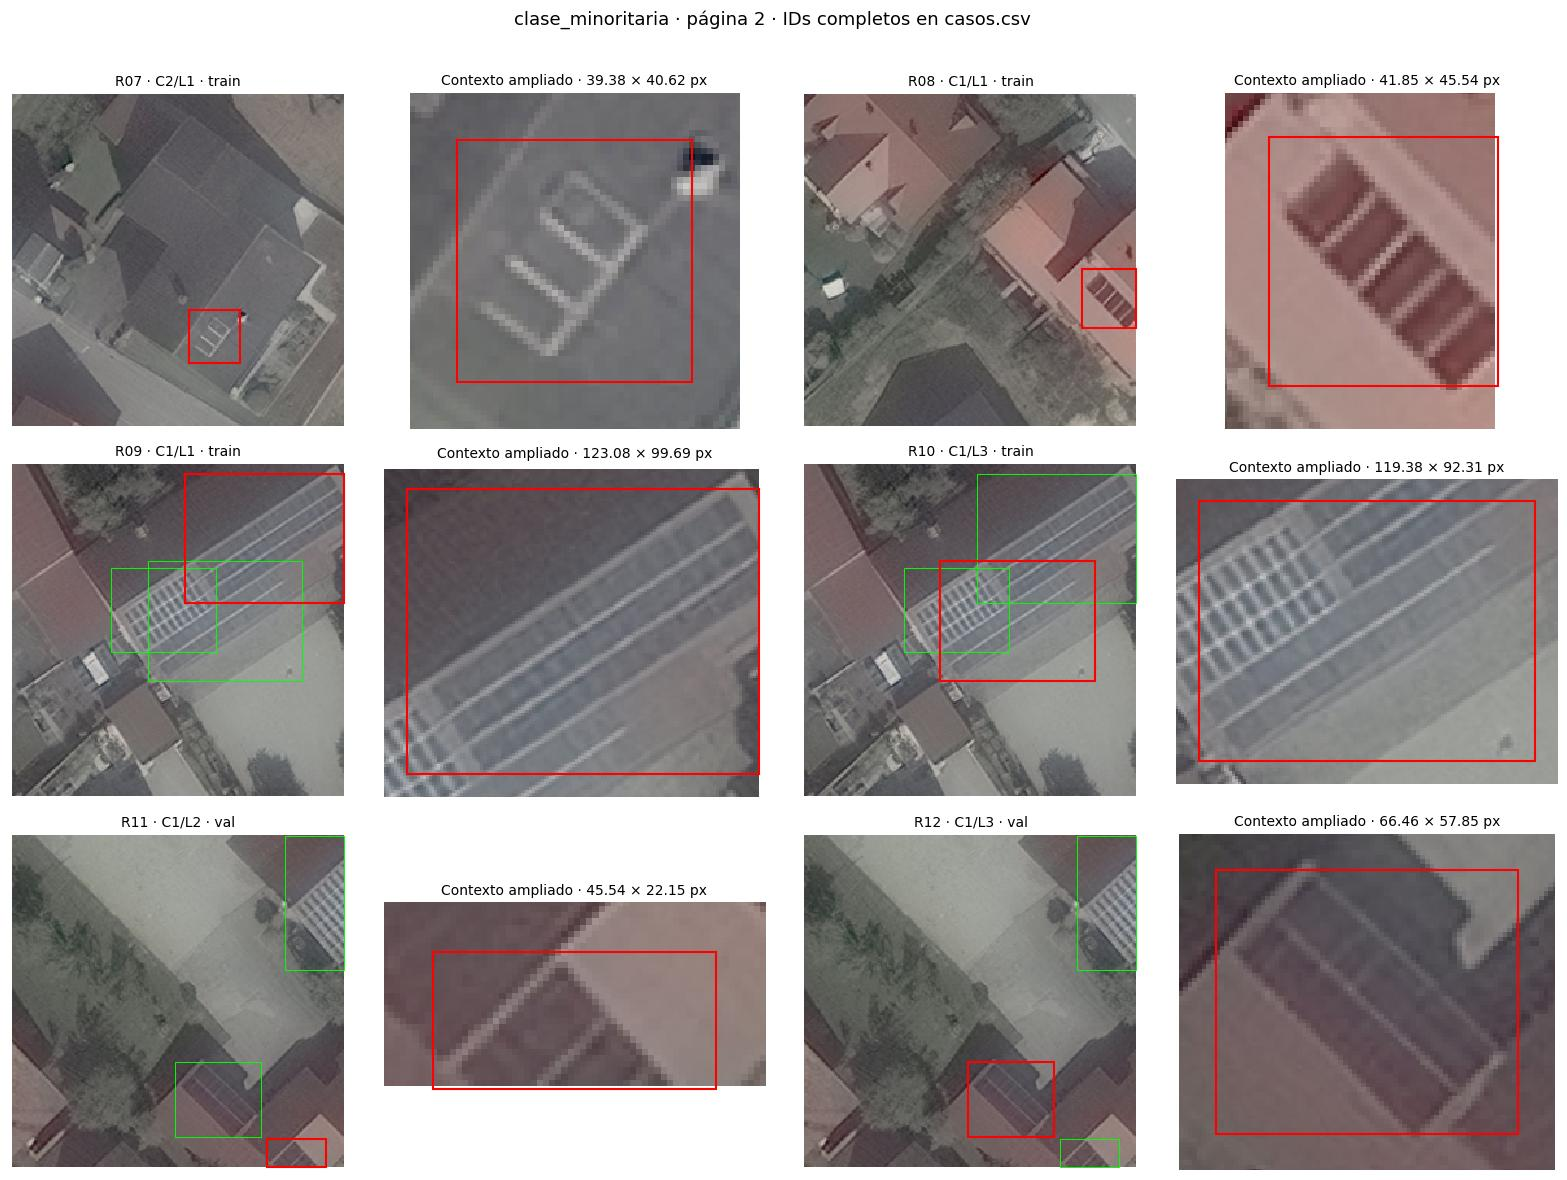

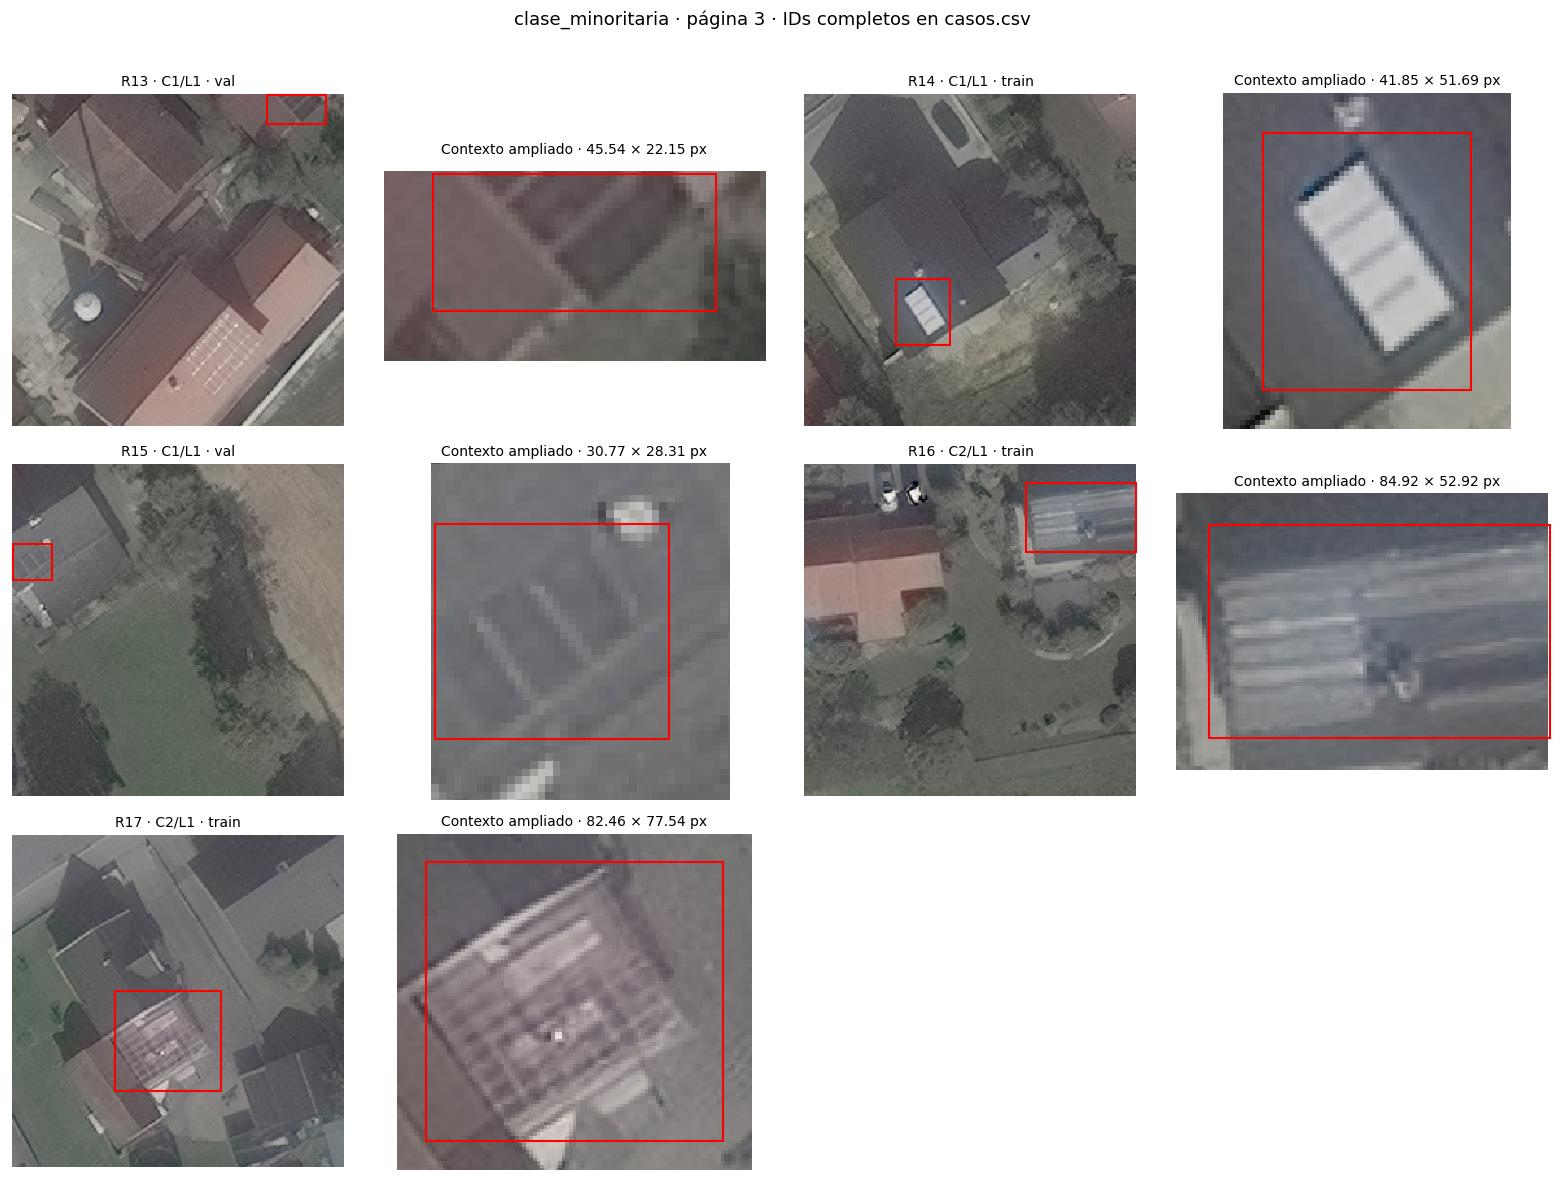

In [3]:
display(pd.read_csv(rutas.repo / "docs" / "cotejo_clases.csv"))
display(revision_completa[revision_completa["categoria"] == "clase_minoritaria"])
for archivo in galerias:
    if archivo.name.startswith("clase_minoritaria_"):
        display(MostrarImagen(filename=str(archivo)))


## Recortes pequeños y caja nula

Se conservan las 37 cajas de tamaño positivo, sin filtro automático a 3 px. Todas
tocan el borde dentro del redondeo de coordenadas. Quitar todas dejaría cuatro
imágenes positivas sin cajas. Z01 tiene ancho cero: solo esa caja se excluirá
cuando se prepare el derivado, manteniendo la imagen y las siete cajas restantes.


,caso,categoria,archivo,linea,clase,split,fuente,w_px,h_px,observacion,decision,estado
17,S01,caja_pequena,PV01_325159_1203813.png,5,0,train,PV01,1.000000,6.000000,Fragmento de borde con muy poca información in...,conservar_recorte_positivo,revisado_visual_Codex
18,S02,caja_pequena,PV01_325190_1204153.png,3,0,train,PV01,2.000000,5.000000,Fragmento de borde con muy poca información in...,conservar_recorte_positivo,revisado_visual_Codex
19,S03,caja_pequena,PV01_325199_1204178.png,1,0,train,PV01,6.000000,2.000000,Fragmento de borde con muy poca información in...,conservar_recorte_positivo,revisado_visual_Codex
20,S04,caja_pequena,PV01_325206_1204153.png,12,0,train,PV01,2.000000,1.000000,Fragmento de borde con muy poca información in...,conservar_recorte_positivo,revisado_visual_Codex
21,S05,caja_pequena,PV01_325206_1204178.png,3,0,train,PV01,1.000000,1.000000,Fragmento de borde con muy poca información in...,conservar_recorte_positivo,revisado_visual_Codex
22,S06,caja_pequena,PV01_325208_1204153.png,1,0,train,PV01,2.000000,1.000000,Fragmento de borde con muy poca información in...,conservar_recorte_positivo,revisado_visual_Codex
23,S07,caja_pequena,PV01_325208_1204161.png,6,0,train,PV01,1.000000,3.000000,Fragmento de borde con muy poca información in...,conservar_recorte_positivo,revisado_visual_Codex
24,S08,caja_pequena,PV01_325208_1204172.png,6,0,train,PV01,1.000000,4.000000,Fragmento de borde con muy poca información in...,conservar_recorte_positivo,revisado_visual_Codex
25,S09,caja_pequena,PV01_325213_1204208.png,1,0,train,PV01,2.000000,5.000000,Fragmento de borde con muy poca información in...,conservar_recorte_positivo,revisado_visual_Codex
26,S10,caja_pequena,PV01_325215_1204200.png,2,0,train,PV01,3.000000,2.000000,Fragmento de borde con muy poca información in...,conservar_recorte_positivo,revisado_visual_Codex


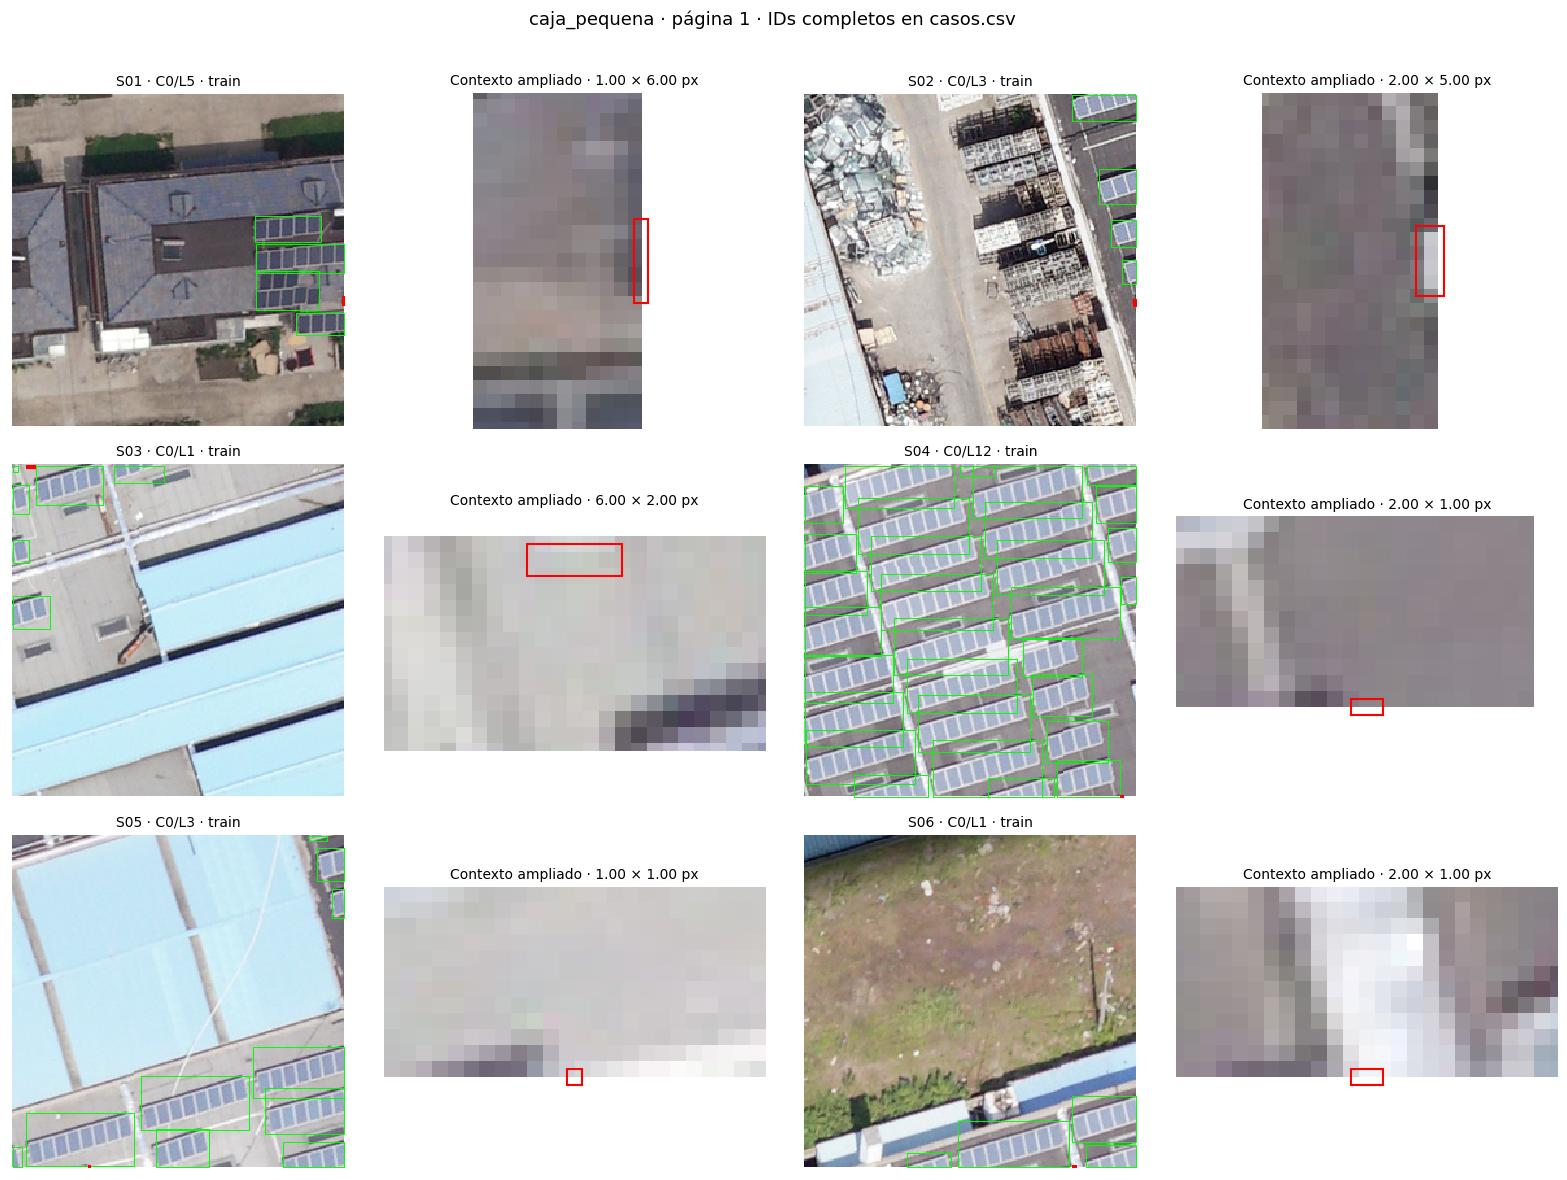

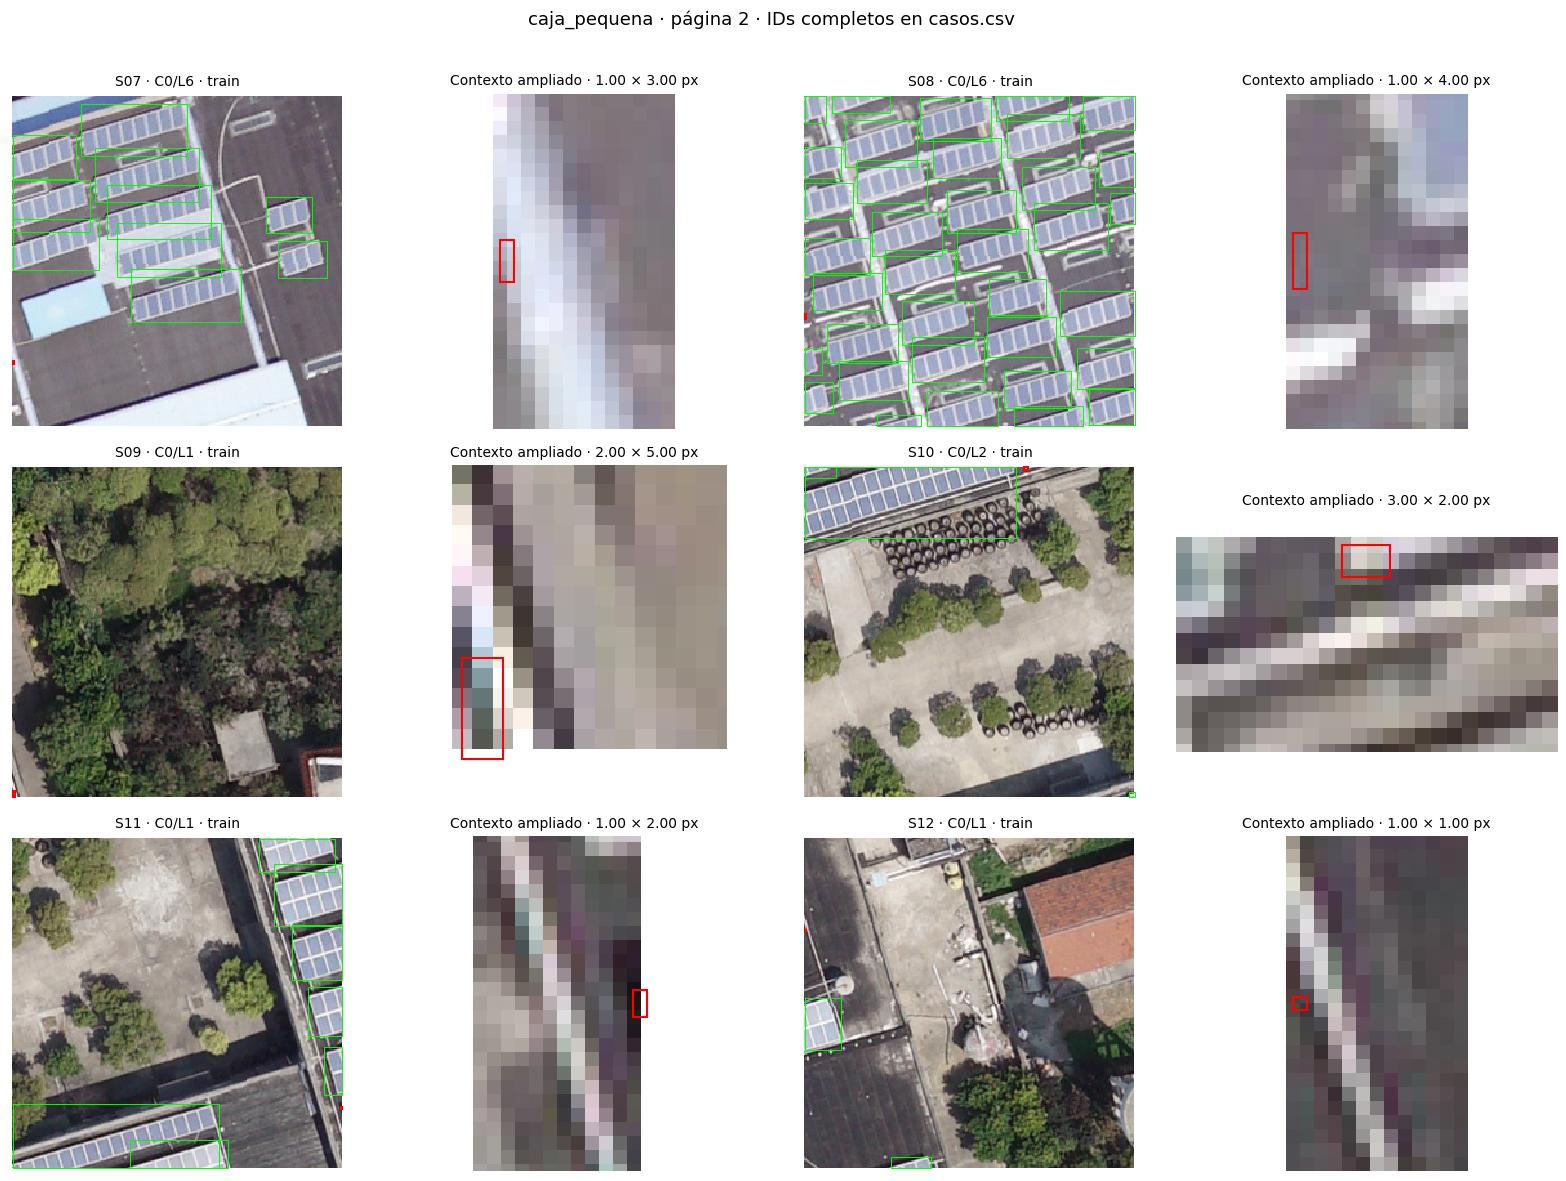

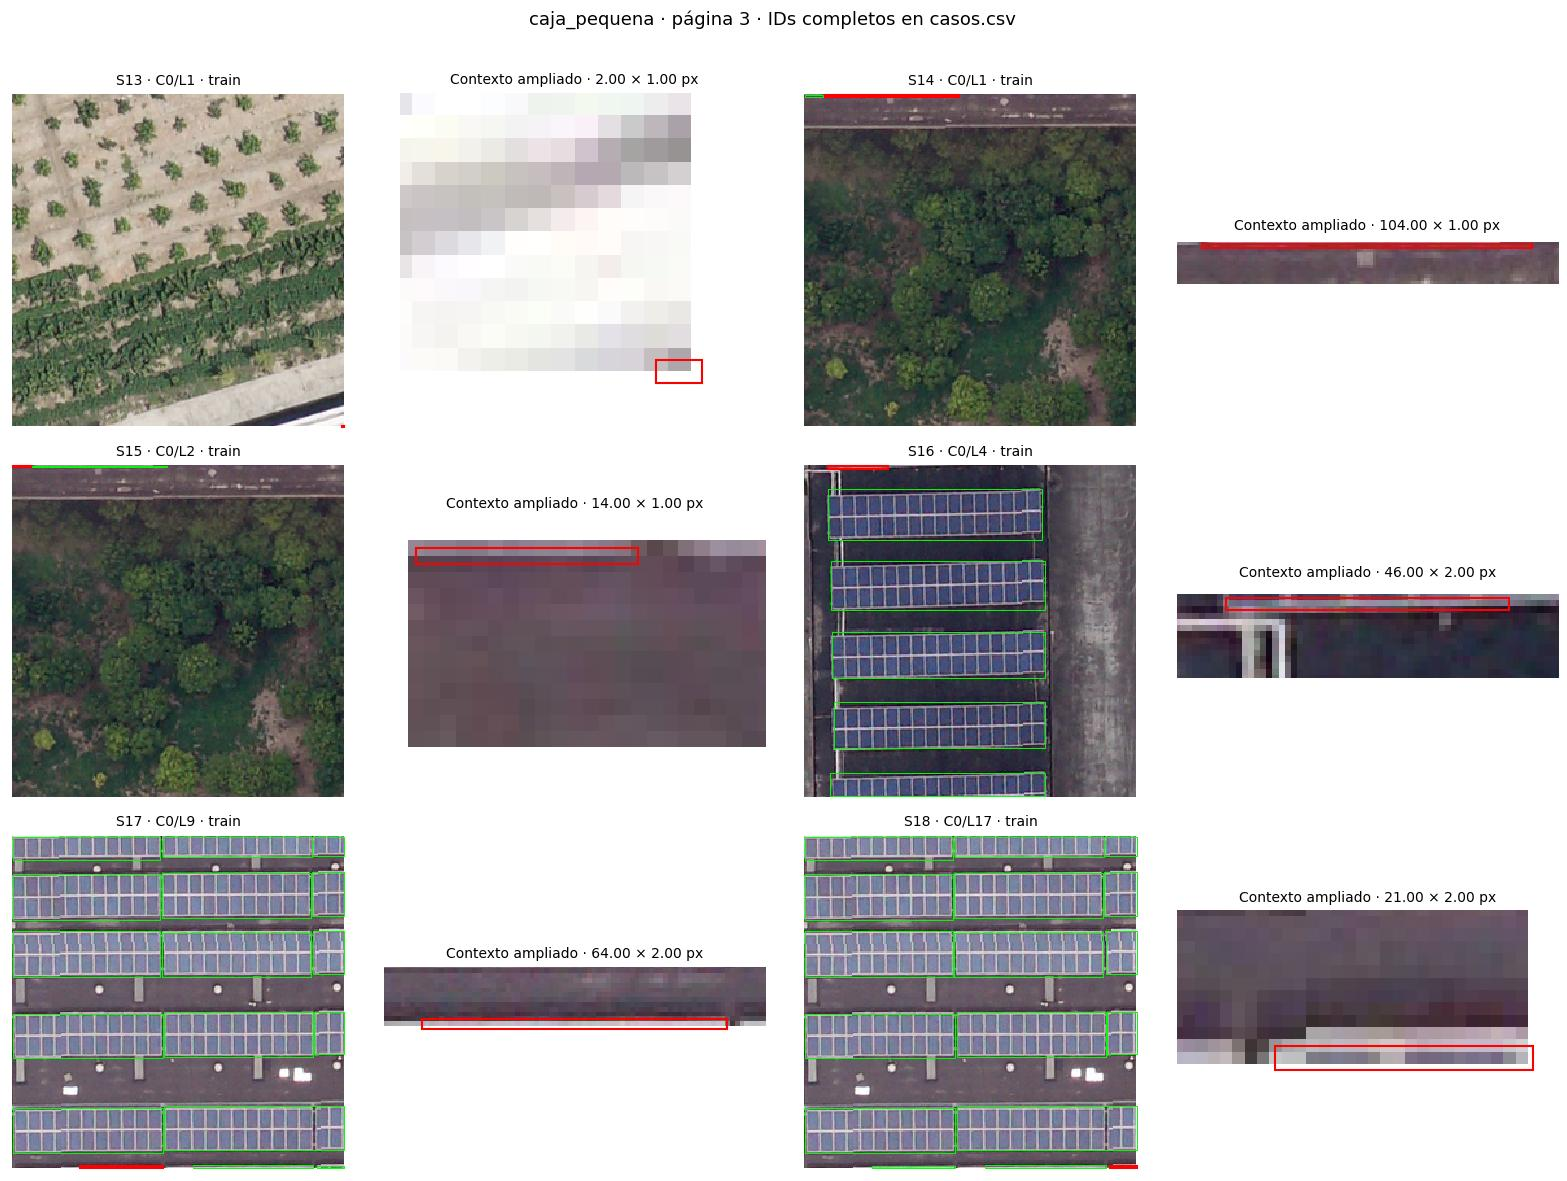

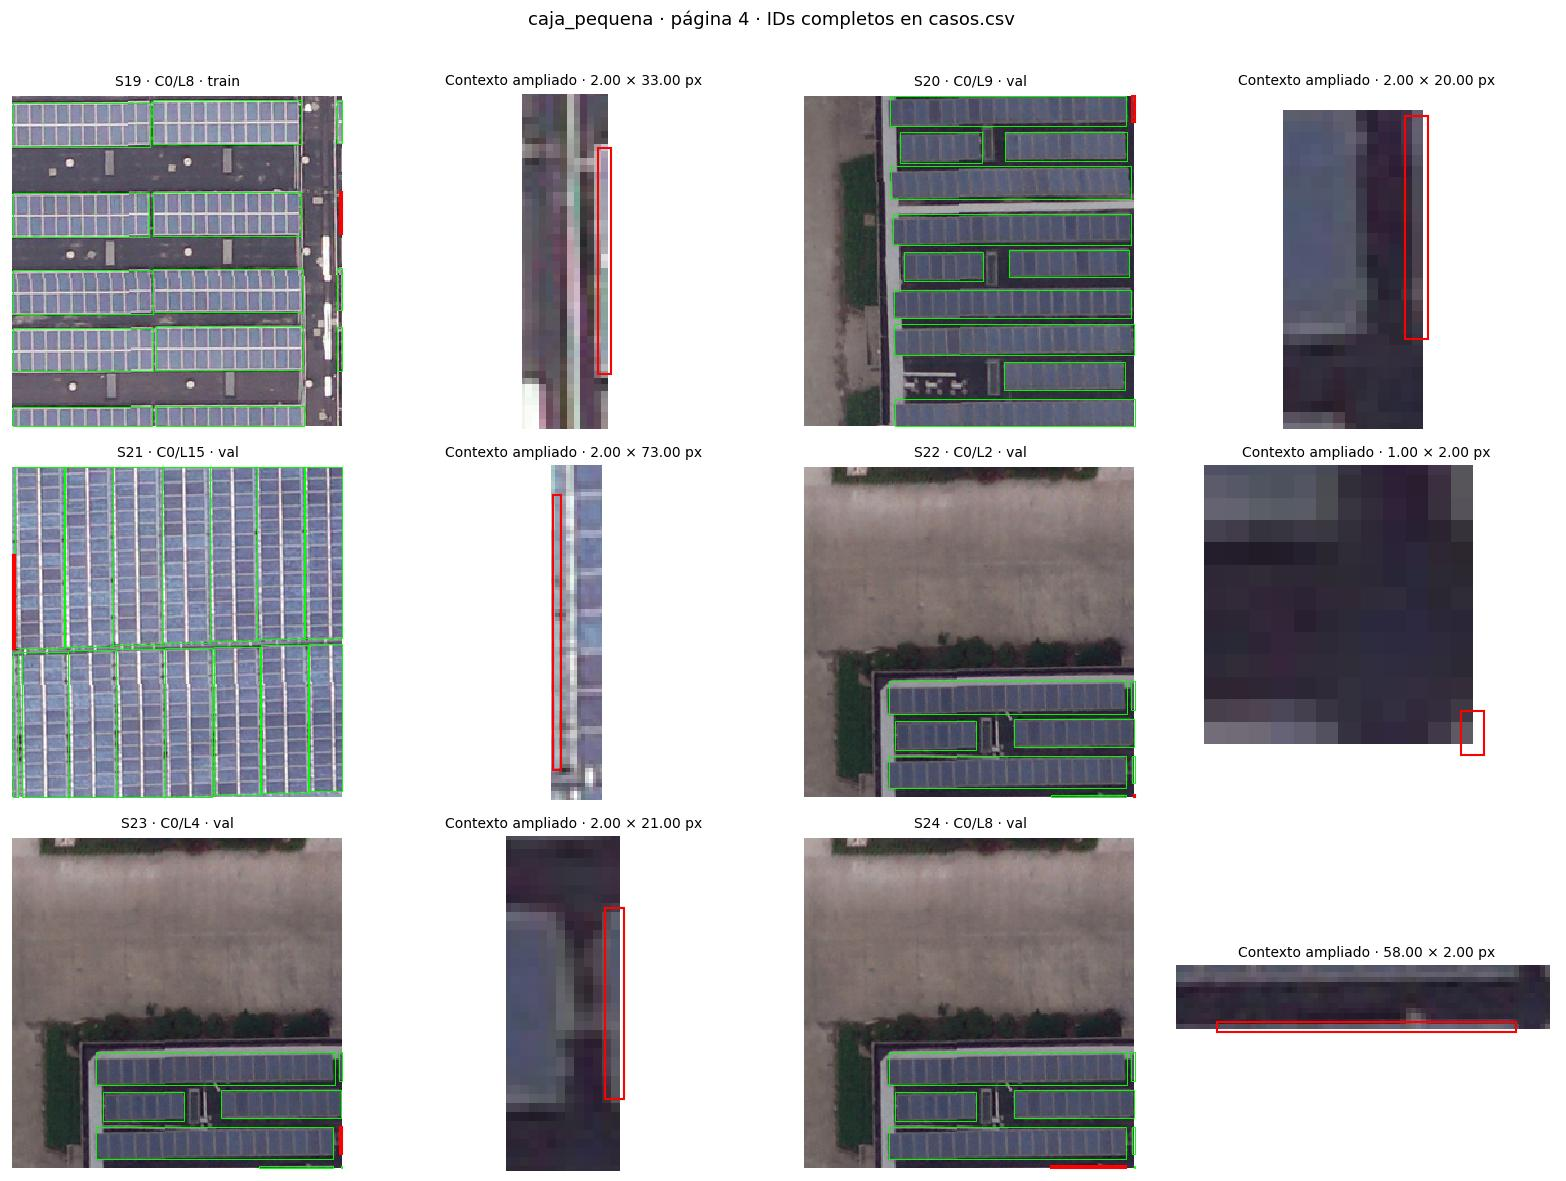

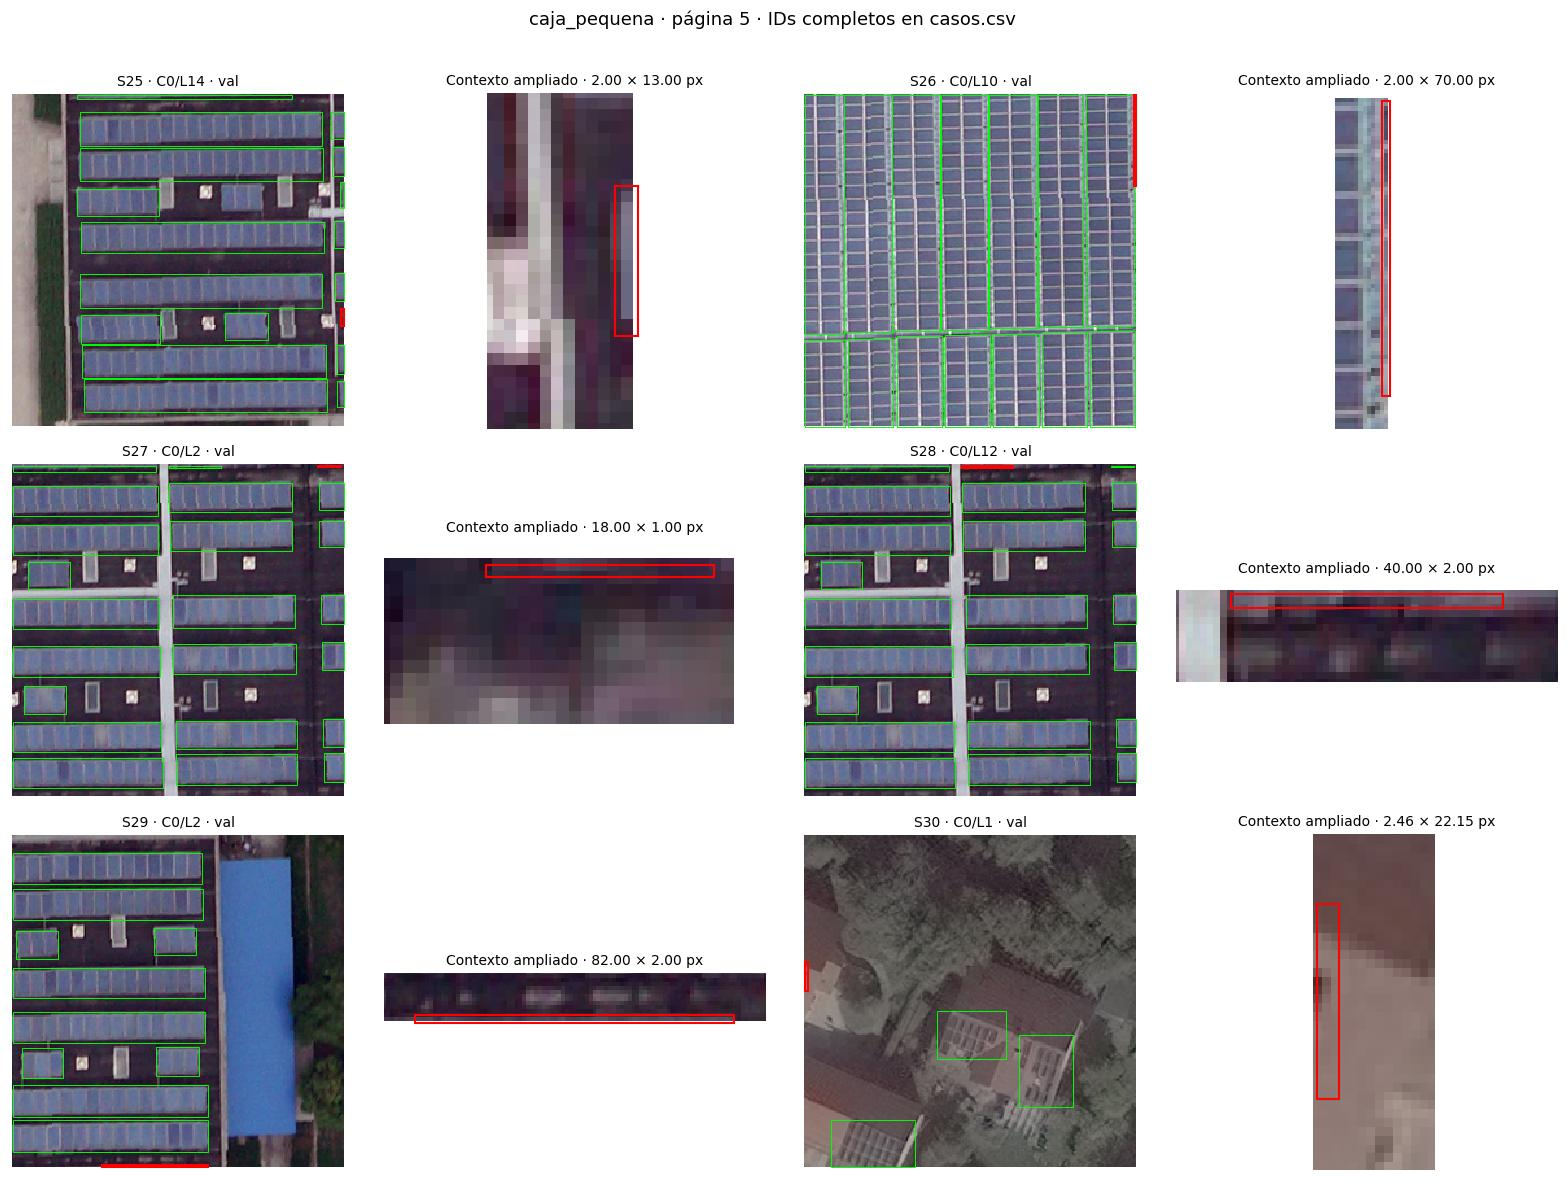

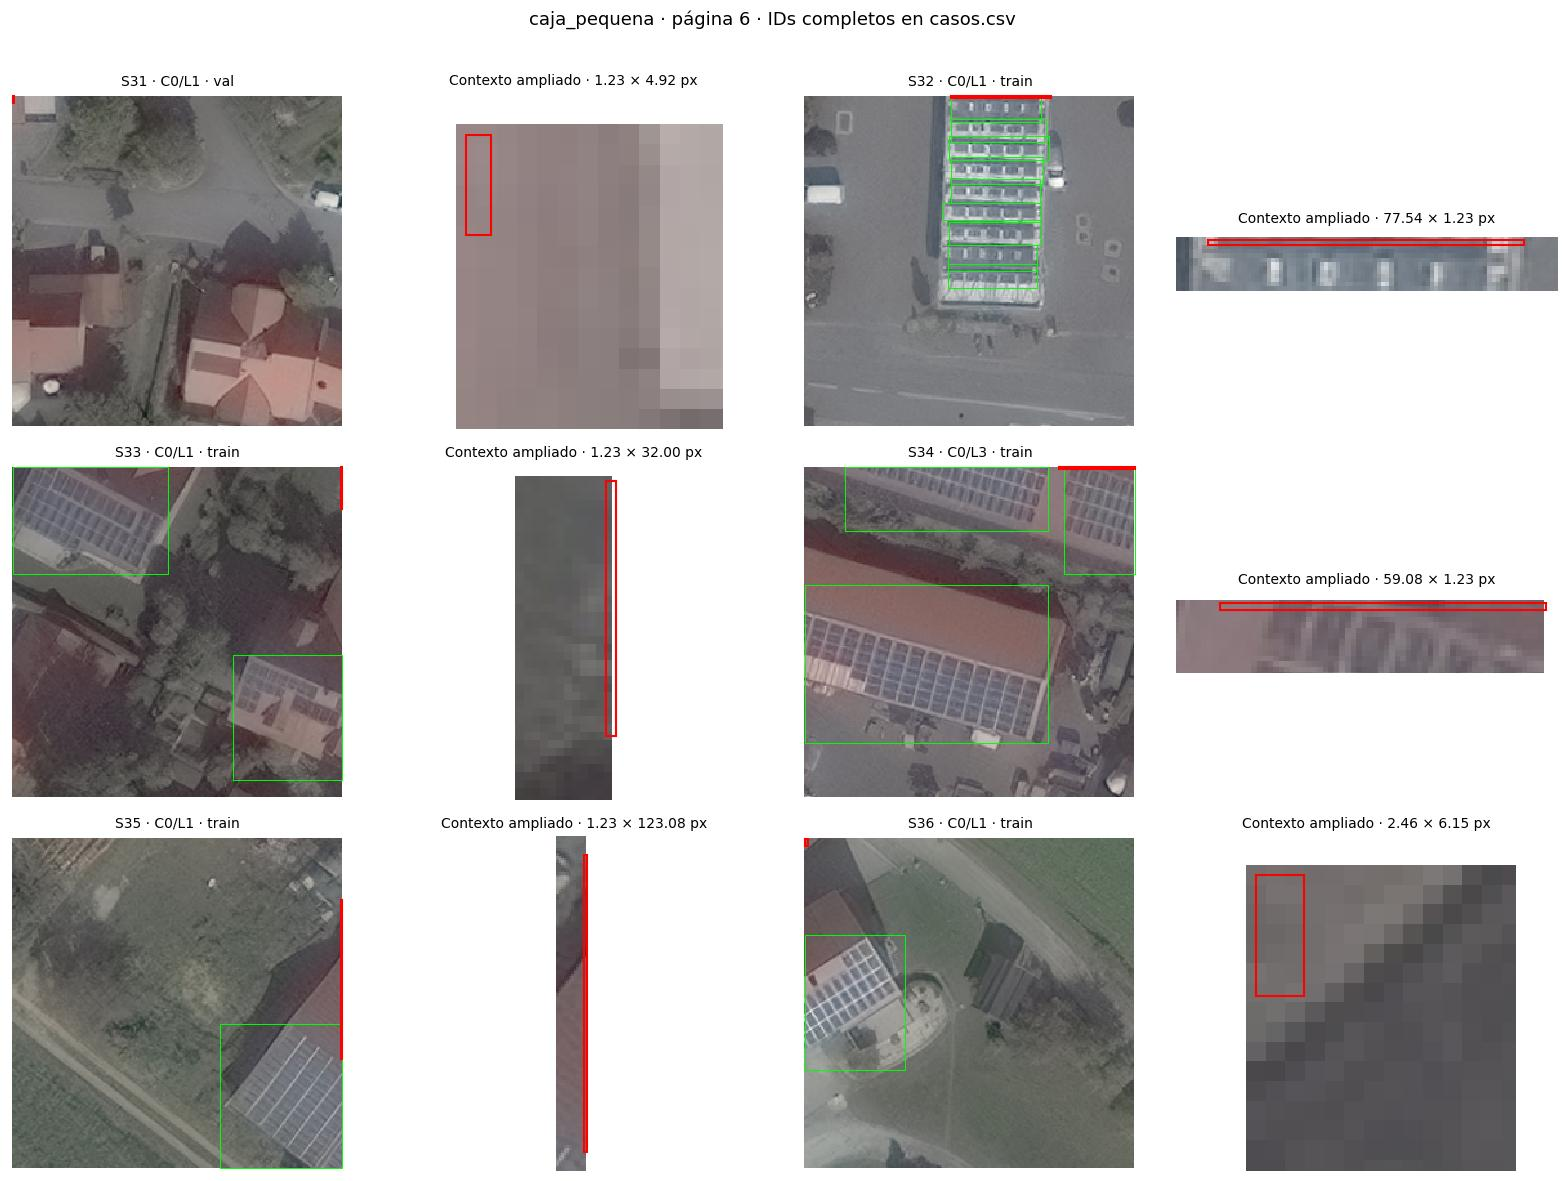

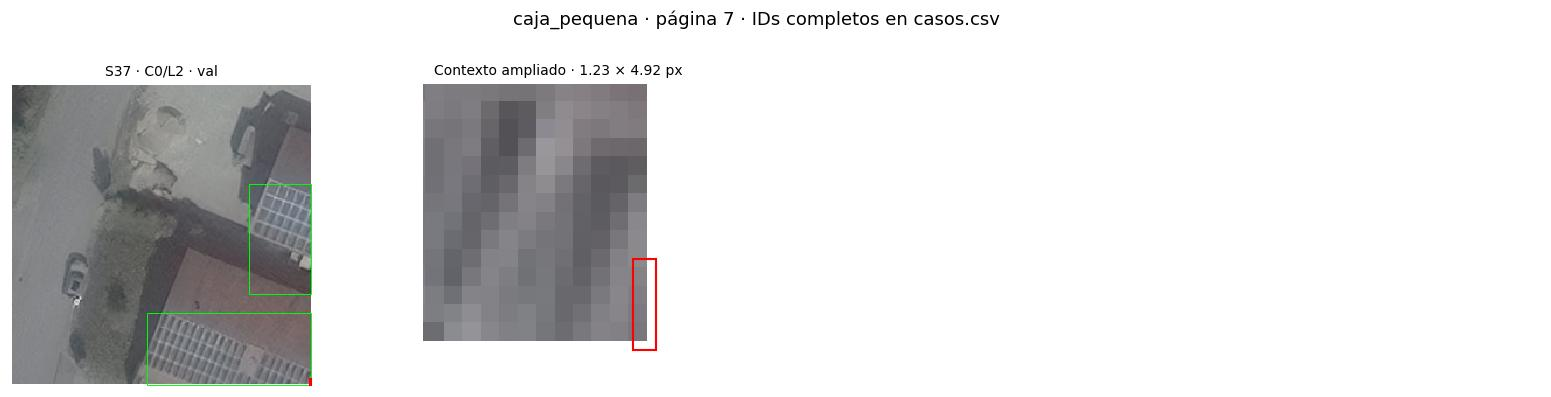

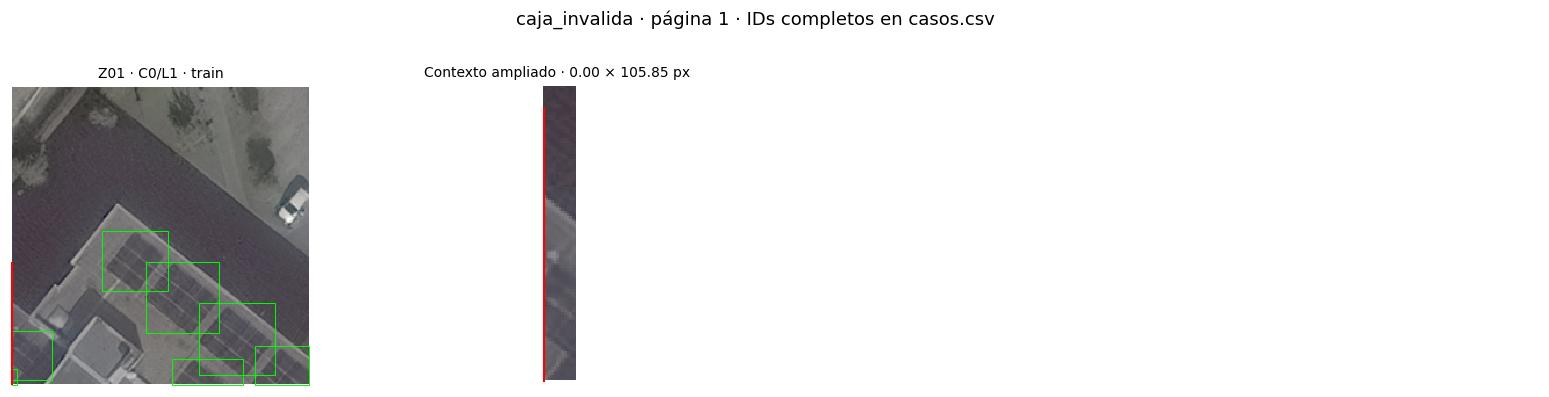

In [4]:
display(revision_completa[revision_completa["categoria"].isin(["caja_pequena", "caja_invalida"])])
for archivo in galerias:
    if archivo.name.startswith(("caja_pequena_", "caja_invalida_")):
        display(MostrarImagen(filename=str(archivo)))


## Muestra con etiqueta vacía

Dieciocho imágenes cubren `geo`, `kingston` y `solarpanels_hd` en ambos splits.
PV01 no aporta negativos. N06 y N16 quedan como ambiguos: revisar con contexto
adicional antes de fijar el conjunto de evaluación, sin reclasificar por intuición.


,caso,categoria,archivo,linea,clase,split,fuente,w_px,h_px,observacion,decision,estado
55,N01,muestra_sin_paneles,2177324_unknown_18.39396513124957_-77.36782528...,<NA>,<NA>,train,geo,NaN,NaN,Sin evidencia visual clara de paneles en esta ...,conservar_etiqueta_vacia,revisado_visual_Codex
56,N02,muestra_sin_paneles,2180210_unknown_18.03136336220585_-76.81583065...,<NA>,<NA>,train,geo,NaN,NaN,Sin evidencia visual clara de paneles en esta ...,conservar_etiqueta_vacia,revisado_visual_Codex
57,N03,muestra_sin_paneles,2182865_unknown_18.388409294653137_-77.0425084...,<NA>,<NA>,train,geo,NaN,NaN,Sin evidencia visual clara de paneles en esta ...,conservar_etiqueta_vacia,revisado_visual_Codex
58,N04,muestra_sin_paneles,2161488_unknown_17.969541515267093_-76.7934515...,<NA>,<NA>,val,geo,NaN,NaN,Sin evidencia visual clara de paneles en esta ...,conservar_etiqueta_vacia,revisado_visual_Codex
59,N05,muestra_sin_paneles,2161488_unknown_17.969541515267093_-76.7934515...,<NA>,<NA>,val,geo,NaN,NaN,Sin evidencia visual clara de paneles en esta ...,conservar_etiqueta_vacia,revisado_visual_Codex
60,N06,muestra_sin_paneles,2165022_unknown_18.160237711023147_-77.4905338...,<NA>,<NA>,val,geo,NaN,NaN,Duda inicial sobre cubierta clara con patrón r...,conservar_etiqueta_vacia,revisado_equipo
61,N07,muestra_sin_paneles,kingston2_71_59_20.png,<NA>,<NA>,train,kingston2,NaN,NaN,Sin evidencia visual clara de paneles en esta ...,conservar_etiqueta_vacia,revisado_visual_Codex
62,N08,muestra_sin_paneles,kingston2_71_59_21.png,<NA>,<NA>,train,kingston2,NaN,NaN,Sin evidencia visual clara de paneles en esta ...,conservar_etiqueta_vacia,revisado_visual_Codex
63,N09,muestra_sin_paneles,kingston2_71_59_5.png,<NA>,<NA>,train,kingston2,NaN,NaN,Sin evidencia visual clara de paneles en esta ...,conservar_etiqueta_vacia,revisado_visual_Codex
64,N10,muestra_sin_paneles,kingston2_1_33_12.png,<NA>,<NA>,val,kingston2,NaN,NaN,Sin evidencia visual clara de paneles en esta ...,conservar_etiqueta_vacia,revisado_visual_Codex


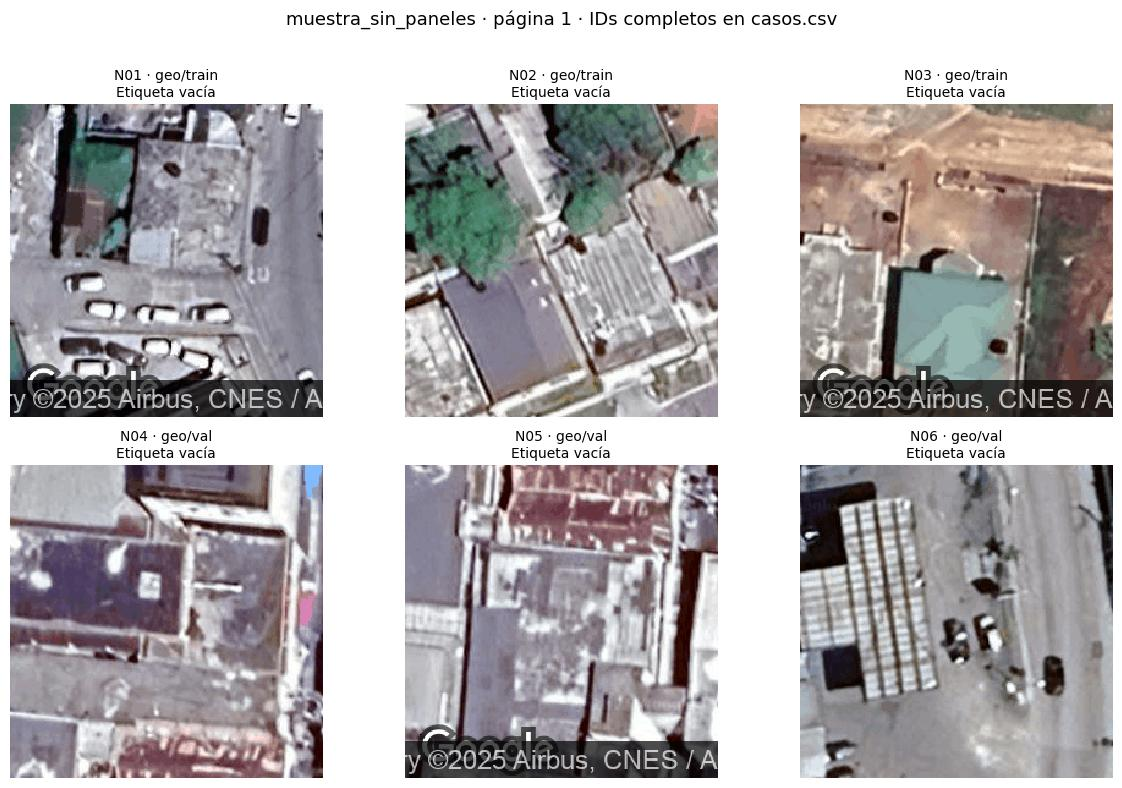

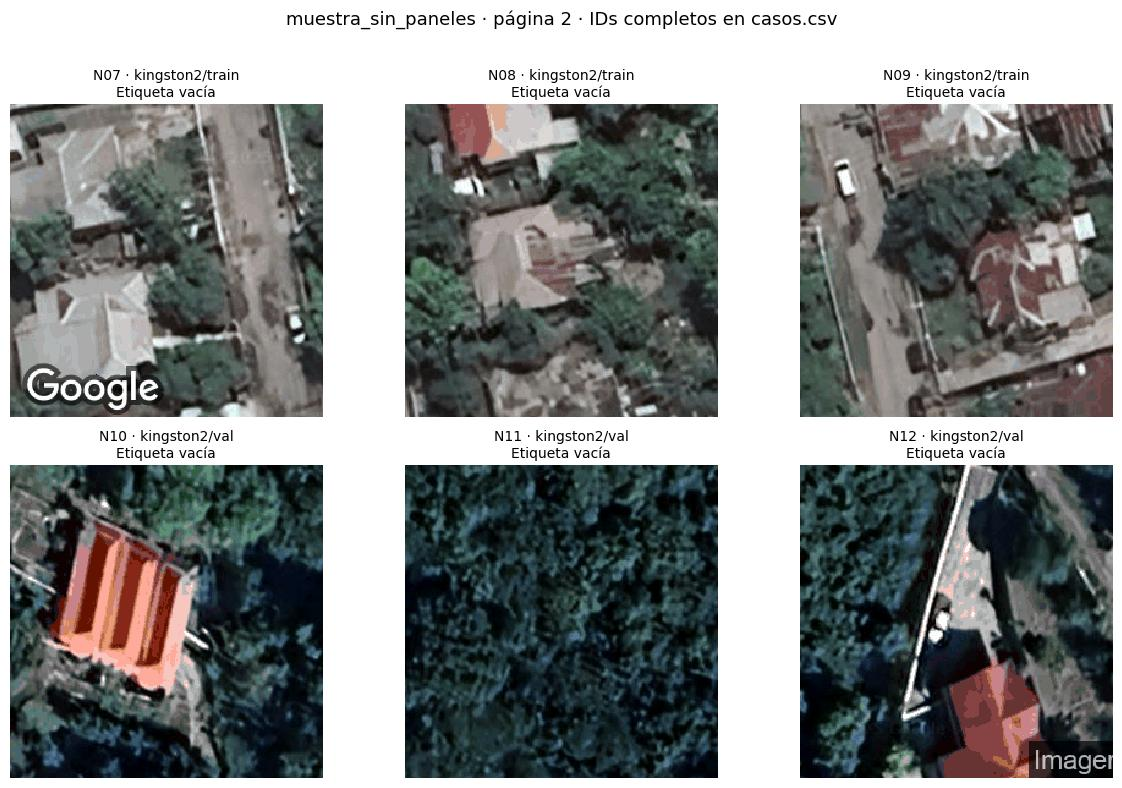

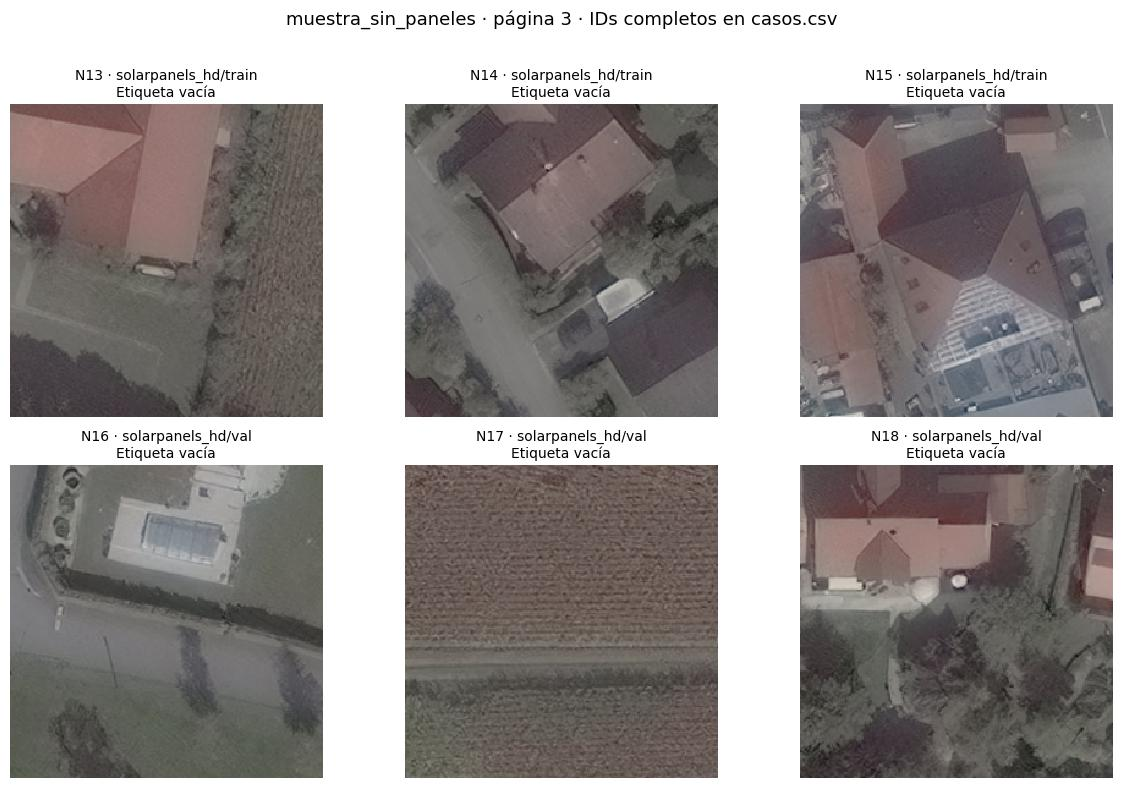

In [5]:
display(revision_completa[revision_completa["categoria"] == "muestra_sin_paneles"])
for archivo in galerias:
    if archivo.name.startswith("muestra_sin_paneles_"):
        display(MostrarImagen(filename=str(archivo)))


## Estado de las decisiones

Los criterios están en `docs/criterios_datos.md`. No se aplicó aún la fusión de clases
ni la exclusión de la caja nula: son reglas para una futura preparación reproducible.
No se cambiaron originales, negativos ni el split. Registrar la segunda revisión de
N06/N16 y la confirmación de alcance de la cátedra antes de cerrar la referencia.
